<a href="https://colab.research.google.com/github/ang-nc/Fisica-computacional-02/blob/main/Taller%203/Ajuste_Lineal_y_Pendulo_Simple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller-Determinación de $g$ con un péndulo

**Parte A**

Limpieza con script

1. Abra `100_mediciones_pendulo_minimos_cuadrados.xlsx` y revise la hoja `Datos_estudiantes`.
2. Ejecute el script de limpieza suministrado por el profesor.
3. Complete sus tres tareas: correcciones justificadas, elección del ángulo máximo y exclusiones manuales.
4. No excluya un dato únicamente porque se aleja de la tendencia. Toda corrección o exclusión debe apoyarse en la información experimental.
5. El script debe generar `pendulo_limpio.dat` e `informe_limpieza.xlsx`.

In [ ]:
# Importa Path para comprobar la existencia de archivos y trabajar con sus rutas.
from pathlib import Path

# Importa pandas para leer, organizar, limpiar y exportar los datos experimentales.
import pandas as pd

# Importa files de Google Colab para descargar los archivos generados al computador.
from google.colab import files


# ============================================================
# 1. LECTURA DEL ARCHIVO
# ============================================================

# Define el nombre del archivo Excel que contiene las mediciones originales.
ARCHIVO_ENTRADA = Path("100_mediciones_pendulo_minimos_cuadrados.xlsx")

# Define el nombre de la hoja de Excel de la cual se leerán los datos.
HOJA = "Datos_estudiantes"

# Comprueba que el archivo Excel exista en el entorno de trabajo de Colab.
# Si no existe, detiene la ejecución y muestra un mensaje explicativo.
if not ARCHIVO_ENTRADA.exists():
    raise FileNotFoundError(
        f"No se encontró {ARCHIVO_ENTRADA}. "
        "Asegúrate de haber subido el archivo al panel lateral de Colab."
    )

# Lee los datos de la hoja seleccionada y los almacena en un DataFrame.
# Un DataFrame es una estructura tabular con filas y columnas.
datos = pd.read_excel(ARCHIVO_ENTRADA, sheet_name=HOJA)

# Define las columnas que deben estar presentes para realizar la limpieza.
# Cada columna contiene información necesaria para identificar o evaluar
# las mediciones experimentales del péndulo.
columnas_requeridas = [
    "medicion_id",
    "longitud_cm",
    "angulo_inicial_deg",
    "numero_oscilaciones",
    "tiempo_medido_s",
    "observador",
    "observacion_campo",
    "calidad_video",
]

# Construye una lista con las columnas requeridas que no aparecen en el archivo.
# La expresión recorre cada nombre de columna y comprueba si existe en datos.
columnas_ausentes = [
    columna for columna in columnas_requeridas if columna not in datos.columns
]

# Si falta alguna columna obligatoria, detiene el programa para evitar
# realizar la limpieza con información incompleta.
if columnas_ausentes:
    raise ValueError(
        "Faltan columnas obligatorias en el archivo: "
        + ", ".join(columnas_ausentes)
    )

# Crea una copia independiente de los datos originales.
# Esta copia permite conservar el conjunto inicial para compararlo
# posteriormente con los datos aceptados y excluidos.
datos_originales = datos.copy(deep=True)

# Muestra la cantidad inicial de registros que contiene el archivo.
print("\nNúmero inicial de registros:", len(datos))


# ============================================================
# 2. COLUMNAS PARA DOCUMENTAR LA LIMPIEZA
# ============================================================

# Crea una columna booleana para indicar si cada registro se conserva.
# True significa que el registro está incluido y False que está excluido.
datos["incluir"] = True

# Registra la acción realizada sobre cada medición.
# Inicialmente, todas las mediciones se consideran conservadas.
datos["accion_limpieza"] = "Conservar"

# Almacena la justificación de la decisión tomada para cada registro.
# Inicialmente, todas las mediciones se consideran aceptadas.
datos["justificacion"] = "Medición aceptada"


# Define una función para excluir registros que cumplen una condición.
# Recibe una condición lógica y el motivo de exclusión.
def excluir_registros(condicion, justificacion):

    # Selecciona los registros que cumplen la condición y que todavía
    # se encuentran incluidos en el conjunto de datos.
    # fillna(False) evita considerar como verdaderas las condiciones
    # cuyo resultado sea un valor ausente.
    nuevos = condicion.fillna(False) & datos["incluir"]

    # Marca los registros seleccionados como excluidos.
    datos.loc[nuevos, "incluir"] = False

    # Registra la acción aplicada a cada registro excluido.
    datos.loc[nuevos, "accion_limpieza"] = "Excluir"

    # Guarda el motivo específico por el cual se excluyó cada registro.
    datos.loc[nuevos, "justificacion"] = justificacion


# ============================================================
# 3. CORRECCIONES JUSTIFICADAS (TODO 1)
# ============================================================

# Diccionario que relaciona el identificador de una medición
# con el valor corregido de su longitud en centímetros.
# En este caso, la medición 52 tiene una longitud corregida de 70 cm.
correcciones_longitud = {
    52: 70  # ID de medición: valor corregido
}

# Diccionario destinado a registrar posibles correcciones de tiempo.
# Está vacío porque no se definieron correcciones de tiempo en esta versión.
correcciones_tiempo = {}

# Recorre cada corrección de longitud definida en el diccionario.
# medicion_id identifica el registro y valor contiene la longitud corregida.
for medicion_id, valor in correcciones_longitud.items():

    # Construye una condición para localizar la medición correspondiente.
    condicion = datos["medicion_id"] == medicion_id

    # Comprueba si existe al menos un registro con ese identificador.
    # Si no existe, muestra una advertencia y continúa con la siguiente corrección.
    if not condicion.any():
        print(f"Advertencia: no existe la medición {medicion_id}.")
        continue

    # Sustituye la longitud registrada por el valor corregido.
    datos.loc[condicion, "longitud_cm"] = valor

    # Registra que se realizó una corrección de longitud.
    datos.loc[condicion, "accion_limpieza"] = "Corregir longitud"

    # Documenta el motivo de la corrección aplicada.
    datos.loc[condicion, "justificacion"] = "Error de registro identificado y corregido"

# Recorre las correcciones de tiempo definidas en el diccionario.
# Como correcciones_tiempo está vacío, este ciclo no modifica ningún registro.
for medicion_id, valor in correcciones_tiempo.items():

    # Localiza la medición que requiere la corrección del tiempo.
    condicion = datos["medicion_id"] == medicion_id

    # Si el identificador no aparece en los datos, informa la situación
    # y continúa sin interrumpir el procesamiento de las demás mediciones.
    if not condicion.any():
        print(f"Advertencia: no existe la medición {medicion_id}.")
        continue

    # Sustituye el tiempo registrado por el valor corregido.
    datos.loc[condicion, "tiempo_medido_s"] = valor

    # Registra que se corrigió el tiempo de la medición.
    datos.loc[condicion, "accion_limpieza"] = "Corregir tiempo"

    # Explica el motivo por el cual se corrigió el tiempo.
    datos.loc[condicion, "justificacion"] = "El valor registrado no correspondía al tiempo total"


# ============================================================
# 4. EXCLUSIONES AUTOMÁTICAS
# ============================================================

# Excluye las mediciones que no tienen registrado un tiempo medido.
# Sin este dato no es posible calcular el período experimental.
excluir_registros(datos["tiempo_medido_s"].isna(), "No existe un tiempo medido")

# Excluye los registros cuyo número de oscilaciones esté ausente
# o sea menor o igual que cero.
# El número de oscilaciones debe ser positivo para calcular el período.
excluir_registros(
    datos["numero_oscilaciones"].isna() | (datos["numero_oscilaciones"] <= 0),
    "Número de oscilaciones ausente o no positivo",
)


# ============================================================
# 5. DOMINIO DE VALIDEZ DEL MODELO (TODO 2)
# ============================================================

# Establece el ángulo máximo permitido, expresado en grados.
# Se utiliza un límite de 10 grados para aplicar la aproximación
# de ángulo pequeño empleada en el modelo del péndulo simple.
ANGULO_MAXIMO = 10

# Comprueba que se haya definido el límite angular.
# Si el valor es None, detiene el programa y solicita completar el TODO 2.
if ANGULO_MAXIMO is None:
    raise ValueError("Debe completar TODO 2: asigne un valor numérico a ANGULO_MAXIMO.")

# Excluye las mediciones cuyo ángulo inicial esté ausente
# o cuyo valor absoluto supere el límite establecido.
# abs() permite evaluar tanto ángulos positivos como negativos.
# fillna(False), dentro de la función de exclusión, gestiona los
# posibles valores ausentes de la condición.
excluir_registros(
    datos["angulo_inicial_deg"].isna() | (datos["angulo_inicial_deg"].abs() > ANGULO_MAXIMO),
    "Fuera de la aproximación de ángulo pequeño",
)


# ============================================================
# 6. BÚSQUEDA DE REGISTROS DUPLICADOS
# ============================================================

# Define las variables experimentales utilizadas para comparar mediciones.
# Dos registros se consideran duplicados cuando coinciden en todas
# estas columnas, independientemente de su identificador.
variables_experimentales = [
    "longitud_cm",
    "angulo_inicial_deg",
    "numero_oscilaciones",
    "tiempo_medido_s",
    "observador",
]

# Crea una serie booleana inicialmente falsa para todos los registros.
# Se utilizará para identificar cuáles corresponden a duplicados.
duplicados = pd.Series(False, index=datos.index)

# Obtiene los índices de los registros que todavía están aceptados.
# La búsqueda de duplicados se realiza únicamente entre ellos.
indices_aceptados = datos.index[datos["incluir"]]

# Busca registros repetidos considerando las variables experimentales.
# keep="first" conserva la primera aparición de cada combinación
# y marca las apariciones posteriores como duplicadas.
duplicados.loc[indices_aceptados] = datos.loc[indices_aceptados].duplicated(
    subset=variables_experimentales, keep="first"
)

# Excluye los registros identificados como duplicados y documenta el motivo.
excluir_registros(duplicados, "Registro experimental duplicado")


# ============================================================
# 7. CÁLCULOS PRELIMINARES E INSPECCIÓN
# ============================================================

# Calcula el período preliminar de cada medición.
# El período corresponde al tiempo total medido dividido entre
# el número de oscilaciones realizadas.
# El resultado se expresa en segundos por oscilación.
# Esta columna sirve como apoyo para inspeccionar los datos.
datos["periodo_preliminar_s"] = datos["tiempo_medido_s"] / datos["numero_oscilaciones"]


# ============================================================
# 8. EXCLUSIONES MANUALES (TODO 3)
# ============================================================

# Define un diccionario con los identificadores de las mediciones
# que deben excluirse manualmente y la justificación de cada decisión.
# Las razones corresponden a problemas identificados durante la
# inspección de los registros experimentales.
exclusiones_manuales = {
    23: "Valor copiado de la pantalla del programa (tiempo anómalo 1.906 s)",
    36: "Calidad de video baja: se perdió el marcador",
    45: "El cronómetro inició tarde",
    77: "Calidad de video baja: se perdió el marcador",
    81: "Valor copiado de la pantalla del programa (tiempo anómalo 1.853 s)",
    88: "Incertidumbre en el número de oscilaciones contadas"
}

# Recorre las exclusiones manuales y obtiene el identificador
# de la medición junto con la razón específica de su exclusión.
for medicion_id, razon in exclusiones_manuales.items():

    # Localiza el registro que coincide con el identificador indicado.
    condicion = datos["medicion_id"] == medicion_id

    # Si la medición no existe, muestra una advertencia y pasa a la siguiente.
    # Esto permite continuar el proceso sin detener toda la limpieza.
    if not condicion.any():
        print(f"Advertencia: no existe la medición {medicion_id}.")
        continue

    # Marca el registro como excluido, independientemente de su estado anterior.
    datos.loc[condicion, "incluir"] = False

    # Registra que la decisión de exclusión fue manual.
    datos.loc[condicion, "accion_limpieza"] = "Excluir"

    # Guarda la justificación particular de la exclusión manual.
    datos.loc[condicion, "justificacion"] = razon


# ============================================================
# 9. CONSTRUCCIÓN DEL CONJUNTO LIMPIO
# ============================================================

# Selecciona únicamente las filas cuyo valor de incluir sea True.
# copy() crea una copia independiente del subconjunto aceptado.
datos_limpios = datos.loc[datos["incluir"]].copy()

# Muestra el número total de registros que había al comenzar la limpieza.
print("\nNúmero de registros originales:", len(datos_originales))

# Muestra cuántos registros quedaron aceptados después de aplicar
# las correcciones y los criterios de exclusión.
print("Número de registros aceptados:", len(datos_limpios))

# Calcula y muestra la cantidad de registros excluidos.
# Se obtiene restando los registros aceptados al total de registros.
print("Número de registros excluidos:", len(datos) - len(datos_limpios))


# ============================================================
# 10. ARCHIVO PARA FORTRAN
# ============================================================

# Define las columnas que se exportarán para que el programa Fortran
# pueda leer los datos necesarios para el ajuste lineal del péndulo.
# Se conserva el identificador junto con las variables experimentales.
columnas_fortran = [
    "medicion_id",
    "longitud_cm",
    "angulo_inicial_deg",
    "numero_oscilaciones",
    "tiempo_medido_s",
]

# Exporta los datos aceptados al archivo de texto pendulo_limpio.dat.
datos_limpios[columnas_fortran].to_csv(
    "pendulo_limpio.dat",

    # Utiliza un espacio como separador entre los valores de cada fila.
    sep=" ",

    # No exporta el índice interno de pandas como una columna adicional.
    index=False,

    # No escribe los nombres de las columnas en la primera fila.
    # Así, el archivo contiene únicamente los datos numéricos.
    header=False,

    # Guarda los valores de punto flotante con seis cifras decimales.
    float_format="%.6f",
)


# ============================================================
# 11. INFORME DE LIMPIEZA Y DESCARGA
# ============================================================

# Selecciona las columnas necesarias para documentar las decisiones
# tomadas durante la limpieza de los datos.
columnas_informe = [
    "medicion_id",
    "incluir",
    "accion_limpieza",
    "justificacion",
]

# Exporta el registro de limpieza a un archivo Excel.
# Se incluye cada medición con su estado, la acción realizada
# y la justificación correspondiente.
# index=False evita añadir una columna con el índice de pandas.
datos[columnas_informe].to_excel("informe_limpieza.xlsx", index=False)

# Informa que el procedimiento de limpieza terminó.
print("\n¡Limpieza completada con éxito!")

# Indica que se iniciará la descarga de los archivos generados.
print("Descargando archivos a tu equipo...")

# Descarga el archivo de datos limpios para utilizarlo en Fortran.
files.download("pendulo_limpio.dat")

# Descarga el informe Excel que documenta las decisiones de limpieza.
files.download("informe_limpieza.xlsx")




Número inicial de registros: 100

Número de registros originales: 100
Número de registros aceptados: 87
Número de registros excluidos: 13

¡Limpieza completada con éxito!
Descargando archivos a tu equipo...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## Parte B. Programa en Fortran 2008

Realice el diagrama de flujo respectivo y escriba el programa `ajuste_pendulo.f90`. El programa debe:

1. Abrir `pendulo_limpio.dat` y comprobar que el archivo se abrió correctamente.
2. Leer un número desconocido de filas mediante un ciclo y `iostat`.
3. Convertir cada longitud de centímetros a metros.
4. Calcular $T$ y construir $x=L$ y $y=T^2$.
5. Acumular $N$, $s_x$, $s_y$, $s_{xx}$ y $s_{xy}$.
6. Calcular la pendiente $a$ y el intercepto $b$.
7. Estimar $g=4\pi^2/a$.
8. Realizar una segunda lectura del archivo para calcular $R^2$.
9. Mostrar claramente $N$, $a$, $b$, $R^2$ y $g$, incluyendo unidades.
10. Escribir esos cinco valores, en ese orden y sin encabezado, en `resultados_ajuste.dat`.
11. Detectar al menos estos errores: archivo inexistente, menos de dos datos y denominador nulo.

Para estandarizar el archivo que revisará la celda PASS/FAIL, declare una unidad de salida entera y use al final del programa:

```fortran
open(newunit=unidad_salida, file='resultados_ajuste.dat', &
     status='replace', action='write')
write(unidad_salida, *) n, a, b, r2, g
close(unidad_salida)
```

Compile con advertencias y comprobaciones activadas:

```bash
gfortran -std=f2008 -Wall -Wextra -fcheck=all -o ajuste_pendulo ajuste_pendulo.f90
./ajuste_pendulo
```

In [ ]:
# Actualiza la lista de paquetes disponibles en los repositorios de Linux.
# La opción -qq reduce la cantidad de mensajes que aparecen en pantalla.
!apt-get update -qq

# Instala el compilador gfortran, necesario para compilar y ejecutar
# programas escritos en Fortran dentro del entorno de Google Colab.
# La opción -y acepta automáticamente las confirmaciones de instalación.
!apt-get install -y gfortran



W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
gfortran is already the newest version (4:13.2.0-7ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 30 not upgraded.


In [ ]:

# Comprueba la versión del compilador gfortran instalado en Google Colab.
# Muestra información sobre el compilador de Fortran disponible en el entorno.
# Esto permite verificar que la instalación se realizó correctamente.
!gfortran --version



GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



In [ ]:
# Importa la herramienta files de Google Colab para gestionar archivos
# que se encuentran en el computador del usuario.
from google.colab import files

# Abre una ventana para seleccionar y cargar archivos desde el computador
# al entorno de trabajo de Google Colab.
# Los archivos seleccionados quedan disponibles para utilizarlos
# en las siguientes celdas del notebook.
files.upload()



Saving pendulo_limpio.dat to pendulo_limpio (1).dat


{'pendulo_limpio (1).dat': b'1 55 8 10 14.975000\n2 90 5 10 19.135000\n3 40 8 10 12.629000\n4 75 5 10 17.416000\n5 25 8 10 9.934000\n6 60 5 10 15.619000\n7 95 8 5 9.882000\n8 45 5 10 13.443000\n9 80 8 10 17.972000\n10 30 5 10 11.057000\n11 80 8 10 17.980000\n13 65 8 10 16.257000\n14 100 5 10 20.006000\n15 50 8 10 14.232000\n16 85 5 10 18.587000\n17 35 8 10 11.842000\n19 20 8 10 8.992000\n20 55 5 10 14.953000\n21 20 8 10 8.974000\n22 55 5 10 14.953000\n24 40 5 10 12.666000\n25 75 8 10 17.352000\n26 25 5 10 10.045000\n27 60 8 10 15.516000\n28 95 5 10 19.557000\n29 45 8 10 13.499000\n30 80 5 10 17.942000\n31 45 8 15 20.172000\n32 80 5 10 17.953000\n33 30 8 10 10.995000\n34 65 5 10 16.169000\n35 100 8 10 20.152000\n37 85 8 10 18.610000\n38 35 5 10 11.865000\n39 70 8 10 16.784000\n40 20 5 10 9.058000\n41 70 8 10 16.907000\n42 20 5 10 9.048000\n43 55 8 10 14.957000\n44 90 5 10 19.114000\n46 75 5 10 17.410000\n48 60 5 10 15.575000\n49 95 8 10 19.614000\n50 45 5 10 13.585000\n51 95 8 10 19.574

In [ ]:
%%writefile ajuste_pendulo.f90
#Este archivo contiene el programa de ajuste lineal del péndulo simple.

Writing ajuste_pendulo.f90


In [ ]:
%%writefile ajuste_pendulo.f90

! Programa para analizar las mediciones de un péndulo simple mediante
! un ajuste lineal por el método de mínimos cuadrados.
! A partir de los datos experimentales, calcula la pendiente, el intercepto,
! el coeficiente de determinación R2 y la aceleración de la gravedad.

program ajuste_pendulo

    ! Evita la declaración implícita de variables y exige que todas
    ! las variables utilizadas se declaren explícitamente.
    implicit none

    !=========================================================
    ! Variables para archivos
    !=========================================================

    ! Identificador interno de la unidad utilizada para leer el archivo.
    integer :: unidad

    ! Identificador interno de la unidad utilizada para guardar resultados.
    integer :: unidad_salida

    ! Código de estado de las operaciones de lectura y apertura.
    ! Un valor igual a cero indica que la operación se realizó correctamente.
    integer :: ios


    !=========================================================
    ! Variables de los datos
    !=========================================================

    ! Identificador de cada medición experimental.
    integer :: medicion_id

    ! Número de oscilaciones realizadas durante la medición del tiempo.
    integer :: numero_oscilaciones

    ! Longitud del péndulo en centímetros, tal como aparece en el archivo.
    real(8) :: longitud_cm

    ! Ángulo inicial de oscilación expresado en grados.
    real(8) :: angulo_inicial_deg

    ! Tiempo total medido experimentalmente, expresado en segundos.
    real(8) :: tiempo_medido_s

    ! Longitud del péndulo convertida a metros.
    ! Se utiliza como variable independiente del ajuste lineal.
    real(8) :: L

    ! Período experimental: tiempo correspondiente a una oscilación,
    ! expresado en segundos.
    real(8) :: T

    ! Cuadrado del período, expresado en segundos cuadrados.
    ! Se utiliza como variable dependiente del ajuste lineal.
    real(8) :: T2


    !=========================================================
    ! Variables para las sumatorias
    !=========================================================

    ! Contador del número de mediciones leídas correctamente.
    integer :: n

    ! Sumatoria de las longitudes: suma de L.
    real(8) :: sx

    ! Sumatoria de los cuadrados de los períodos: suma de T^2.
    real(8) :: sy

    ! Sumatoria de los cuadrados de las longitudes: suma de L^2.
    real(8) :: sxx

    ! Sumatoria de los productos entre longitud y período al cuadrado:
    ! suma de L*T^2.
    real(8) :: sxy


    !=========================================================
    ! Variables del ajuste
    !=========================================================

    ! Pendiente de la recta de ajuste, con unidades s^2/m.
    real(8) :: a

    ! Intercepto de la recta con el eje vertical, con unidades s^2.
    real(8) :: b

    ! Aceleración experimental de la gravedad, con unidades m/s^2.
    real(8) :: g


    !=========================================================
    ! Variables para R2
    !=========================================================

    ! Valor de T^2 predicho por la recta de ajuste para cada longitud.
    real(8) :: y_ajuste

    ! Promedio de los valores experimentales de T^2.
    real(8) :: y_prom

    ! Suma de los cuadrados de las diferencias entre los valores
    ! experimentales y los valores predichos por la recta.
    real(8) :: ss_res

    ! Suma de los cuadrados de las diferencias entre los valores
    ! experimentales y el promedio de T^2.
    real(8) :: ss_tot

    ! Coeficiente de determinación: permite evaluar qué tan bien
    ! representa la recta de ajuste los datos experimentales.
    real(8) :: r2


    !=========================================================
    ! Constante pi
    !=========================================================

    ! Define el valor de pi con precisión de doble precisión.
    ! La palabra parameter indica que su valor permanece constante.
    real(8), parameter :: pi = 3.14159265358979323846d0


    !=========================================================
    ! Inicialización
    !=========================================================

    ! Inicializa el contador de mediciones en cero.
    n   = 0

    ! Inicializa en cero las sumatorias que se utilizarán
    ! para calcular los coeficientes del ajuste lineal.
    sx  = 0.0d0
    sy  = 0.0d0
    sxx = 0.0d0
    sxy = 0.0d0


    !=========================================================
    ! 1. Abrir pendulo_limpio.dat
    !=========================================================

    ! Abre el archivo de datos limpios en modo lectura.
    ! newunit asigna automáticamente una unidad disponible.
    ! status='old' exige que el archivo ya exista.
    ! action='read' indica que solo se leerán datos.
    ! iostat=ios permite comprobar si la apertura fue exitosa.
    open(newunit=unidad, file='pendulo_limpio.dat', &
         status='old', action='read', iostat=ios)

    ! Si la apertura falla, muestra un mensaje y detiene el programa.
    if (ios /= 0) then
        print *, 'ERROR: no se pudo abrir pendulo_limpio.dat'
        stop
    end if


    !=========================================================
    ! 2-5. Primera lectura de los datos
    !=========================================================

    ! Inicia un ciclo que permite leer una cantidad desconocida de filas.
    ! El ciclo termina cuando la lectura devuelve un estado distinto de cero,
    ! por ejemplo, al llegar al final del archivo.
    do

        ! Lee los cinco valores de cada fila del archivo:
        ! identificador, longitud, ángulo, oscilaciones y tiempo medido.
        ! iostat registra si la lectura fue correcta o si llegó al final.
        read(unidad, *, iostat=ios) medicion_id, longitud_cm, &
            angulo_inicial_deg, numero_oscilaciones, tiempo_medido_s

        ! Si la lectura no fue exitosa, sale del ciclo.
        if (ios /= 0) exit


        !-----------------------------------------------------
        ! 3. Convertir longitud de cm a m
        !-----------------------------------------------------

        ! Convierte la longitud de centímetros a metros.
        ! Se divide entre 100 porque 100 cm equivalen a 1 m.
        L = longitud_cm / 100.0d0


        !-----------------------------------------------------
        ! 4. Calcular periodo T y T^2
        !-----------------------------------------------------

        ! Calcula el período dividiendo el tiempo total medido
        ! entre el número de oscilaciones realizadas.
        T = tiempo_medido_s / dble(numero_oscilaciones)

        ! Calcula el cuadrado del período.
        ! El operador ** representa una potencia en Fortran.
        T2 = T**2


        !-----------------------------------------------------
        ! 5. Acumular sumatorias
        !-----------------------------------------------------

        ! Incrementa el contador por cada registro leído correctamente.
        n   = n + 1

        ! Acumula la suma de las longitudes L.
        sx  = sx  + L

        ! Acumula la suma de los cuadrados de los períodos T^2.
        sy  = sy  + T2

        ! Acumula la suma de los cuadrados de las longitudes L^2.
        sxx = sxx + L**2

        ! Acumula la suma de los productos L*T^2.
        sxy = sxy + L*T2

    end do

    ! Cierra el archivo después de completar la primera lectura.
    close(unidad)


    !=========================================================
    ! 11. Comprobar que haya al menos dos datos
    !=========================================================

    ! Comprueba que se hayan leído al menos dos mediciones.
    ! Con menos de dos datos no se puede determinar una recta
    ! de ajuste lineal a partir de las mediciones.
    if (n < 2) then
        print *, 'ERROR: se necesitan al menos dos datos.'
        stop
    end if


    !=========================================================
    ! 6. Calcular pendiente e intercepto
    !=========================================================

    ! Comprueba que el denominador de las fórmulas del ajuste
    ! lineal no sea cero, para evitar una división indefinida.
    if (dble(n)*sxx - sx**2 == 0.0d0) then
        print *, 'ERROR: denominador nulo en el ajuste.'
        stop
    end if

    ! Calcula la pendiente a de la recta de mínimos cuadrados:
    !
    ! a = [n*sum(L*T^2) - sum(L)*sum(T^2)] /
    !     [n*sum(L^2) - (sum(L))^2]
    !
    ! Esta pendiente describe cómo cambia T^2 con respecto a L.
    ! dble(n) convierte el contador entero a doble precisión
    ! para realizar las operaciones con números reales.
    a = (dble(n)*sxy - sx*sy) / &
        (dble(n)*sxx - sx**2)

    ! Calcula el intercepto b de la recta de ajuste:
    !
    ! b = [sum(T^2) - a*sum(L)] / n
    !
    ! El intercepto representa el valor extrapolado de T^2
    ! cuando la longitud L es igual a cero.
    b = (sy - a*sx) / dble(n)


    !=========================================================
    ! 7. Calcular g
    !=========================================================

    ! Para un péndulo simple y ángulos pequeños se cumple:
    !
    ! T^2 = (4*pi^2/g)*L
    !
    ! Por comparación con la recta T^2 = a*L + b,
    ! la pendiente teórica corresponde a a = 4*pi^2/g.
    ! Despejando, se obtiene la gravedad experimental:
    !
    ! g = 4*pi^2/a
    !
    ! El resultado se expresa en metros por segundo al cuadrado.
    g = 4.0d0*pi**2 / a


    !=========================================================
    ! Promedio de y
    !=========================================================

    ! Calcula el promedio de los valores de T^2.
    ! Este promedio se utilizará para calcular la suma total
    ! de cuadrados necesaria para obtener el coeficiente R2.
    y_prom = sy / dble(n)


    !=========================================================
    ! 8. Segunda lectura para calcular R2
    !=========================================================

    ! Inicializa las sumas de cuadrados en cero.
    ! ss_res mide la discrepancia entre los datos y la recta.
    ! ss_tot mide la variabilidad total de los datos respecto al promedio.
    ss_res = 0.0d0
    ss_tot = 0.0d0


    ! Abre nuevamente el archivo para recorrer los datos una segunda vez.
    ! Se necesita esta segunda lectura para comparar cada dato observado
    ! con su valor predicho por la recta de ajuste.
    open(newunit=unidad, file='pendulo_limpio.dat', &
         status='old', action='read', iostat=ios)

    ! Si no es posible volver a abrir el archivo, informa el error
    ! y detiene la ejecución.
    if (ios /= 0) then
        print *, 'ERROR: no se pudo abrir nuevamente el archivo.'
        stop
    end if


    ! Recorre de nuevo todas las filas del archivo para calcular R2.
    do

        ! Lee nuevamente los cinco valores de cada medición.
        read(unidad, *, iostat=ios) medicion_id, longitud_cm, &
            angulo_inicial_deg, numero_oscilaciones, tiempo_medido_s

        ! Termina la lectura al llegar al final del archivo
        ! o si ocurre algún error de lectura.
        if (ios /= 0) exit


        !-----------------------------------------------------
        ! Reconstruir L y T^2
        !-----------------------------------------------------

        ! Convierte nuevamente la longitud de centímetros a metros.
        L = longitud_cm / 100.0d0

        ! Reconstruye el período experimental de la medición.
        T = tiempo_medido_s / dble(numero_oscilaciones)

        ! Calcula el cuadrado del período observado.
        T2 = T**2


        !-----------------------------------------------------
        ! Valor predicho por el ajuste
        !-----------------------------------------------------

        ! Calcula el valor de T^2 predicho por la recta:
        !
        ! y_ajuste = a*L + b
        !
        ! Este valor se compara con el T^2 experimental.
        y_ajuste = a*L + b


        !-----------------------------------------------------
        ! Suma de cuadrados de residuos
        !-----------------------------------------------------

        ! Calcula el cuadrado de la diferencia entre el valor
        ! experimental T2 y el valor predicho y_ajuste.
        ! La suma de estas diferencias al cuadrado constituye ss_res.
        ss_res = ss_res + (T2 - y_ajuste)**2


        !-----------------------------------------------------
        ! Suma total de cuadrados
        !-----------------------------------------------------

        ! Calcula el cuadrado de la diferencia entre el valor
        ! experimental T2 y el promedio y_prom.
        ! La acumulación de estas diferencias constituye ss_tot.
        ss_tot = ss_tot + (T2 - y_prom)**2

    end do

    ! Cierra el archivo después de calcular las sumas de cuadrados.
    close(unidad)


    !=========================================================
    ! Comprobar denominador de R2
    !=========================================================

    ! Comprueba que exista variabilidad en los valores experimentales.
    ! Si ss_tot es cero, no se puede calcular R2 con esta fórmula.
    if (ss_tot == 0.0d0) then
        print *, 'ERROR: denominador nulo al calcular R2.'
        stop
    end if


    !=========================================================
    ! Calcular R2
    !=========================================================

    ! Calcula el coeficiente de determinación mediante:
    !
    ! R2 = 1 - ss_res/ss_tot
    !
    ! Un valor cercano a 1 indica que la recta representa
    ! adecuadamente la variación observada en los datos.
    r2 = 1.0d0 - ss_res/ss_tot


    !=========================================================
    ! 9. Mostrar resultados
    !=========================================================

    ! Imprime una línea en blanco para separar la salida anterior.
    print *

    ! Presenta un encabezado para identificar los resultados del programa.
    print *, '=========================================='
    print *, '          AJUSTE DEL PENDULO'
    print *, '=========================================='

    ! Muestra el número de mediciones procesadas.
    print *, 'N  = ', n

    ! Muestra la pendiente del ajuste, expresada en s^2/m.
    print *, 'a  = ', a, ' s^2/m'

    ! Muestra el intercepto de la recta, expresado en s^2.
    print *, 'b  = ', b, ' s^2'

    ! Muestra el coeficiente de determinación del ajuste.
    print *, 'R2 = ', r2

    ! Muestra la aceleración experimental de la gravedad, en m/s^2.
    print *, 'g  = ', g, ' m/s^2'

    ! Cierra visualmente el bloque de resultados.
    print *, '=========================================='


    !=========================================================
    ! 10. Guardar resultados
    !=========================================================

    ! Abre el archivo de salida para guardar los cinco resultados.
    ! status='replace' crea el archivo si no existe o reemplaza
    ! su contenido anterior si ya existe.
    ! action='write' indica que se utilizará para escribir.
    open(newunit=unidad_salida, file='resultados_ajuste.dat', &
         status='replace', action='write')

    ! Escribe en una sola línea los resultados en este orden:
    ! número de datos, pendiente, intercepto, R2 y gravedad.
    ! No se incluye una cabecera, para facilitar la lectura posterior.
    write(unidad_salida, *) n, a, b, r2, g

    ! Cierra el archivo después de guardar los resultados.
    close(unidad_salida)


! Finaliza el programa principal.
end program ajuste_pendulo



Overwriting ajuste_pendulo.f90


In [ ]:
# Muestra la lista de archivos y carpetas que se encuentran
# en el directorio actual de trabajo de Google Colab.
# Permite comprobar si están presentes los archivos necesarios
# para continuar con el taller, como el archivo de datos .dat
# y el programa de Fortran .f90.
!ls



100_mediciones_pendulo_minimos_cuadrados.xlsx  pendulo_limpio.dat
ajuste_pendulo.f90			       sample_data
informe_limpieza.xlsx


In [ ]:
# Compila el archivo fuente ajuste_pendulo.f90 utilizando gfortran.
# Genera el programa ejecutable llamado ajuste_pendulo.
#
# -std=f2008: exige el estándar Fortran 2008.
# -Wall: activa un conjunto amplio de advertencias del compilador.
# -Wextra: activa advertencias adicionales para detectar posibles problemas.
# -fcheck=all: habilita comprobaciones en tiempo de ejecución
# para detectar determinados errores durante la ejecución del programa.
# -o ajuste_pendulo: establece el nombre del archivo ejecutable generado.
# ajuste_pendulo.f90: identifica el archivo fuente que se va a compilar.

!gfortran -std=f2008 -Wall -Wextra -fcheck=all -o ajuste_pendulo ajuste_pendulo.f90



ajuste_pendulo.f90:246:20:

  246 |     if (dble(n)*sxx - sx**2 == 0.0d0) then
      |                    1
ajuste_pendulo.f90:393:8:

  393 |     if (ss_tot == 0.0d0) then
      |        1


In [ ]:
# Ejecuta el programa compilado de Fortran llamado ajuste_pendulo.
# El programa lee los datos del archivo pendulo_limpio.dat,
# realiza el ajuste lineal por mínimos cuadrados y calcula
# el coeficiente de determinación R² y la aceleración de la gravedad.
# Finalmente, muestra los resultados en pantalla y los guarda
# en el archivo resultados_ajuste.dat.
!./ajuste_pendulo




           AJUSTE DEL PENDULO
 N  =           87
 a  =    4.0494334936484542       s^2/m
 b  =   -3.1597771405320252E-003  s^2
 R2 =   0.99974198065251996     
 g  =    9.7491211218259100       m/s^2


In [1]:
# Muestra en pantalla el contenido del archivo resultados_ajuste.dat.
# Este archivo contiene los cinco resultados calculados por el programa Fortran:
# 1. N: número de datos utilizados en el ajuste.
# 2. a: pendiente de la recta de ajuste, en s²/m.
# 3. b: intercepto de la recta de ajuste, en s².
# 4. R²: coeficiente de determinación que indica la calidad del ajuste.
# 5. g: aceleración de la gravedad calculada, en m/s².
# Los valores están guardados en una sola línea y no incluyen encabezados.
!cat resultados_ajuste.dat



cat: resultados_ajuste.dat: No such file or directory


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Muestra la lista de archivos y carpetas que se encuentran
# en el directorio actual de trabajo de Google Colab.
# Permite comprobar si están presentes los archivos necesarios
# para continuar con el taller, como el archivo de datos .dat
# y el programa de Fortran .f90.
!ls

100_mediciones_pendulo_minimos_cuadrados.xlsx  pendulo_limpio.dat
ajuste_pendulo				       resultados_ajuste.dat
ajuste_pendulo.f90			       sample_data
informe_limpieza.xlsx


In [ ]:

# Importa la herramienta files de Google Colab para gestionar archivos.
from google.colab import files

# Descarga el archivo fuente de Fortran ajuste_pendulo.f90 al computador.
# Este archivo contiene el código del programa que realiza el ajuste lineal
# de los datos del péndulo simple y calcula la aceleración de la gravedad.
files.download('ajuste_pendulo.f90')



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Descarga el archivo resultados_ajuste.dat al computador.
# Este archivo contiene los resultados numéricos obtenidos por el programa Fortran:
# el número de datos, la pendiente, el intercepto, el coeficiente R²
# y el valor calculado de la aceleración de la gravedad.
files.download('resultados_ajuste.dat')



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Parte C. Visualización en Python

Complete la celda para representar $T^2$ en función de $L$, la recta calculada con Fortran y los residuos. No use Python para volver a realizar el ajuste: los valores de `a` y `b` deben proceder de su programa Fortran.

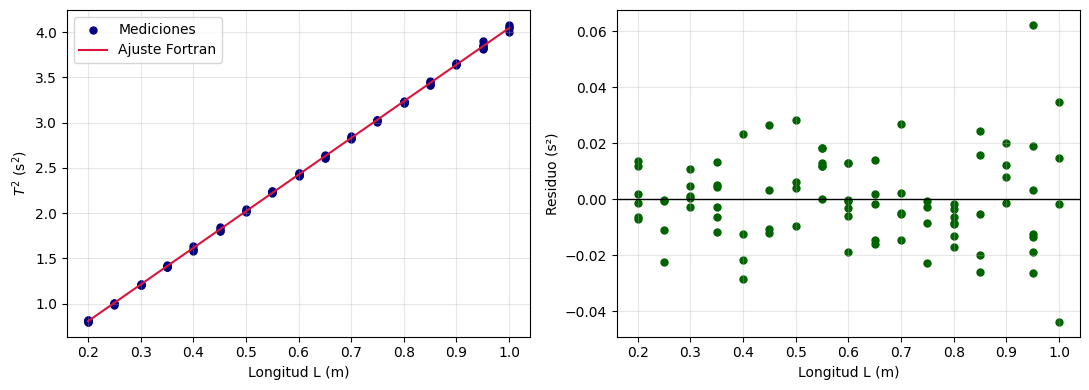

In [ ]:
# Importa NumPy para trabajar con los datos numéricos y realizar cálculos.
import numpy as np

# Importa Matplotlib para construir las gráficas de los resultados.
import matplotlib.pyplot as plt

# Lee las cinco columnas del archivo de datos limpios generado
# previamente por el script de limpieza.
datos = np.loadtxt("pendulo_limpio.dat")

# Convierte la longitud de centímetros a metros para trabajar
# con las unidades del Sistema Internacional.
longitud_m = datos[:, 1] / 100.0

# Extrae el número de oscilaciones registrado en cada medición.
numero_oscilaciones = datos[:, 3]

# Extrae el tiempo total medido para cada conjunto de oscilaciones,
# expresado en segundos.
tiempo_total_s = datos[:, 4]

# Calcula el período de una oscilación dividiendo el tiempo total
# entre el número de oscilaciones registradas.
periodo_s = tiempo_total_s / numero_oscilaciones

# Define la longitud del péndulo como la variable independiente x.
x = longitud_m

# Eleva al cuadrado el período para obtener la variable dependiente y.
# De esta manera, el modelo físico se expresa mediante una relación lineal
# entre el cuadrado del período y la longitud del péndulo.
y = periodo_s**2

# Define la pendiente y el intercepto calculados por el programa Fortran.
# Se utilizan directamente estos valores para representar el ajuste,
# sin volver a calcular la regresión lineal en Python.
a = 4.0494334936484542
b = -0.0031597771405320252

# Obtiene los índices que ordenan las longitudes de menor a mayor.
# Este orden se utilizará para dibujar la recta de ajuste de forma continua.
orden = np.argsort(x)

# Calcula los valores de T² predichos por la recta de ajuste de Fortran
# mediante el modelo lineal y = ax + b.
y_ajustada = a*x + b

# Calcula los residuos como la diferencia entre los valores medidos
# y los valores predichos por el modelo lineal.
# Los residuos permiten evaluar las diferencias entre los datos
# experimentales y la recta de ajuste.
residuos = y - y_ajustada

# Crea una figura con dos paneles organizados horizontalmente.
# El primero mostrará las mediciones y la recta de ajuste;
# el segundo mostrará los residuos.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# Representa las mediciones experimentales como puntos.
# El eje horizontal corresponde a la longitud y el vertical a T².
ax1.scatter(x, y, s=25, color="navy", label="Mediciones")

# Dibuja la recta de ajuste obtenida con los parámetros de Fortran.
# Se utilizan las longitudes ordenadas para evitar que la línea
# conecte los puntos en un orden irregular.
ax1.plot(x[orden], y_ajustada[orden],
         color="crimson", label="Ajuste Fortran")

# Asigna el nombre y la unidad del eje horizontal.
ax1.set_xlabel("Longitud L (m)")

# Asigna el nombre y la unidad del eje vertical.
ax1.set_ylabel(r"$T^2$ (s$^2$)")

# Añade una cuadrícula tenue para facilitar la lectura de la gráfica.
ax1.grid(alpha=0.3)

# Muestra la leyenda para distinguir las mediciones de la recta de ajuste.
ax1.legend()

# Dibuja una línea horizontal en cero como referencia para los residuos.
# Los residuos positivos indican que el valor medido supera al ajustado,
# mientras que los negativos indican que el valor medido es inferior.
ax2.axhline(0.0, color="black", linewidth=1)

# Representa los residuos en función de la longitud del péndulo.
ax2.scatter(x, residuos, s=25, color="darkgreen")

# Asigna el nombre y la unidad del eje horizontal de la gráfica de residuos.
ax2.set_xlabel("Longitud L (m)")

# Asigna el nombre y la unidad del eje vertical de la gráfica de residuos.
ax2.set_ylabel("Residuo (s²)")

# Añade una cuadrícula para facilitar la interpretación de los residuos.
ax2.grid(alpha=0.3)

# Ajusta automáticamente los espacios entre los paneles y sus etiquetas
# para evitar que los elementos de la figura se superpongan.
plt.tight_layout()

# Guarda la figura generada en un archivo PNG que se incluirá
# entre los resultados del taller y podrá adjuntarse al informe.
# La resolución de 200 dpi mejora la calidad de la imagen.
# bbox_inches="tight" reduce los márgenes vacíos alrededor de la figura.
plt.savefig("ajuste_pendulo_y_residuos.png",
            dpi=200, bbox_inches="tight")

# Muestra la figura con las mediciones, la recta de ajuste
# y la gráfica de los residuos en la salida de Google Colab.
plt.show()



In [ ]:
# Importa la herramienta files de Google Colab para gestionar archivos.
from google.colab import files

# Descarga la imagen ajuste_pendulo_y_residuos.png al computador.
# Esta figura contiene dos gráficas:
# 1. Las mediciones experimentales de T² en función de la longitud L,
#    junto con la recta de ajuste calculada mediante el programa Fortran.
# 2. Los residuos del ajuste lineal en función de la longitud del péndulo.
# La imagen se puede incluir en el informe del Taller 3.
files.download("ajuste_pendulo_y_residuos.png")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Parte D. Informe de una página

Entregue un informe en PDF usando la plantilla LaTeX suministrada. Debe ocupar **una sola página**. Si el contenido excede una página, resuma las ideas; no reduzca la fuente ni cambie los márgenes.

In [ ]:
# Importa Path para comprobar la existencia y el tamaño de los archivos.
from pathlib import Path

# Importa NumPy para leer los datos y realizar cálculos numéricos
# que permitan verificar de manera independiente los resultados de Fortran.
import numpy as np

# Crea una lista vacía para almacenar el resultado booleano de cada prueba.
# True representa una prueba superada y False una prueba fallida.
resultados_pruebas = []

# Define una función auxiliar para mostrar un veredicto uniforme por prueba.
# Recibe el nombre de la prueba, una condición que debe cumplirse
# y un detalle opcional con información adicional.
def informar(nombre, condicion, detalle=""):
    # Selecciona PASS si la condición se cumple o FAIL si no se cumple.
    estado = "PASS" if condicion else "FAIL"

    # Imprime el estado, el nombre de la prueba y el detalle correspondiente.
    print(f"{estado:<4}  {nombre}{detalle}")

    # Guarda el resultado de la condición como un valor booleano.
    resultados_pruebas.append(bool(condicion))

    # Devuelve el resultado para permitir utilizarlo en otras comprobaciones.
    return bool(condicion)

# Define las rutas de los archivos que debe generar el flujo de trabajo:
# los datos limpios, los resultados numéricos y la figura final.
archivo_datos = Path("pendulo_limpio.dat")
archivo_resultados = Path("resultados_ajuste.dat")
archivo_figura = Path("ajuste_pendulo_y_residuos.png")

# Primer nivel de verificación: comprueba si los archivos existen
# antes de intentar leer su contenido.
ok_datos = informar("Existe pendulo_limpio.dat", archivo_datos.exists())
ok_resultados = informar("Existe resultados_ajuste.dat", archivo_resultados.exists())

# Verifica que la figura exista y que su tamaño sea mayor que cero.
# Si el archivo no existe, la condición se considera falsa.
informar("Existe la figura", archivo_figura.exists() and archivo_figura.stat().st_size > 0 if archivo_figura.exists() else False)

# Segundo nivel de verificación: si los archivos de datos y resultados
# existen, intenta leerlos para validar sus estructuras y contenidos.
if ok_datos and ok_resultados:
    try:
        # Lee los datos limpios y garantiza que el resultado tenga
        # al menos dos dimensiones, incluso si contiene una sola fila.
        datos = np.atleast_2d(np.loadtxt(archivo_datos))

        # Lee los resultados de Fortran y organiza todos sus valores
        # en un vector unidimensional.
        resultados = np.loadtxt(archivo_resultados).reshape(-1)

        # Comprueba que el archivo de datos tenga cinco columnas
        # y al menos dos filas para poder realizar el ajuste lineal.
        estructura_datos = datos.shape[1] == 5 and datos.shape[0] >= 2

        # Comprueba que el archivo de resultados contenga exactamente
        # cinco valores numéricos.
        estructura_resultados = resultados.size == 5

        # Informa si la estructura del archivo de datos es correcta,
        # mostrando el número de filas y columnas encontradas.
        informar("Formato del archivo de datos", estructura_datos, f"  filas={datos.shape[0]}, columnas={datos.shape[1]}")

        # Informa si el archivo de resultados contiene los cinco valores
        # esperados y muestra cuántos valores fueron encontrados.
        informar("Formato del archivo de resultados", estructura_resultados, f"  valores={resultados.size}")

        # Continúa con las comprobaciones numéricas solamente si ambos
        # archivos tienen la estructura esperada.
        if estructura_datos and estructura_resultados:
            # Reconstruye las variables del modelo lineal a partir
            # de los datos limpios, sin utilizar los resultados de Fortran.
            # Convierte la longitud de centímetros a metros.
            longitud_m = datos[:, 1] / 100.0

            # Calcula el período de cada oscilación dividiendo el tiempo
            # total entre el número de oscilaciones registradas.
            periodo_s = datos[:, 4] / datos[:, 3]

            # Define la longitud como variable independiente x.
            x = longitud_m

            # Define el cuadrado del período como variable dependiente y.
            y = periodo_s**2

            # Determina el número de mediciones disponibles.
            n_ref = len(x)

            # Calcula las sumas necesarias para aplicar el método
            # de mínimos cuadrados de manera independiente.
            sx = np.sum(x)
            sy = np.sum(y)
            sxx = np.sum(x*x)
            sxy = np.sum(x*y)

            # Calcula el denominador de las expresiones de la pendiente
            # y el intercepto de la recta de ajuste.
            den = n_ref*sxx - sx*sx

            # Calcula la pendiente de referencia mediante la fórmula
            # de mínimos cuadrados para el modelo y = ax + b.
            a_ref = (n_ref*sxy - sx*sy) / den

            # Calcula el intercepto de referencia utilizando la pendiente
            # obtenida y los promedios de las variables.
            b_ref = (sy - a_ref*sx) / n_ref

            # Calcula los residuos de referencia como la diferencia
            # entre los valores medidos y los valores ajustados.
            residuos_ref = y - (a_ref*x + b_ref)

            # Calcula la suma de los cuadrados de los residuos (SSE),
            # que cuantifica las diferencias entre el modelo y los datos.
            sse_ref = np.sum(residuos_ref**2)

            # Calcula la suma total de cuadrados (SST), que mide
            # la variabilidad de los datos respecto a su media.
            sst_ref = np.sum((y - np.mean(y))**2)

            # Calcula el coeficiente de determinación R².
            # Un valor cercano a 1 indica que el modelo lineal
            # explica una gran proporción de la variabilidad observada.
            r2_ref = 1.0 - sse_ref/sst_ref

            # Calcula la aceleración de la gravedad de referencia
            # a partir de la pendiente y la relación del péndulo simple:
            # a = 4π²/g, por lo que g = 4π²/a.
            g_ref = 4.0*np.pi**2/a_ref

            # Desempaqueta los cinco valores guardados por el programa
            # Fortran, respetando el orden del archivo de resultados.
            n_f, a_f, b_f, r2_f, g_f = resultados

            # Comprueba que el número de datos informado por Fortran
            # coincida con el número de mediciones utilizadas.
            informar("Número de datos N", int(round(n_f)) == n_ref, f"  obtenido={n_f:g}, esperado={n_ref}")

            # Compara la pendiente de Fortran con la calculada
            # independientemente en Python.
            # np.isclose utiliza tolerancias relativas y absolutas
            # para considerar pequeñas diferencias numéricas.
            informar("Pendiente a", np.isclose(a_f, a_ref, rtol=1e-6, atol=1e-9), f"  obtenida={a_f:.8g}, esperada={a_ref:.8g}")

            # Comprueba que el intercepto calculado por Fortran
            # coincida con el valor de referencia.
            informar("Intercepto b", np.isclose(b_f, b_ref, rtol=1e-6, atol=1e-9), f"  obtenido={b_f:.8g}, esperado={b_ref:.8g}")

            # Verifica que el coeficiente de determinación R²
            # coincida con el calculado de forma independiente.
            informar("Coeficiente R²", np.isclose(r2_f, r2_ref, rtol=1e-6, atol=1e-9), f"  obtenido={r2_f:.8g}, esperado={r2_ref:.8g}")

            # Comprueba que la aceleración de la gravedad entregada
            # por Fortran coincida con el valor de referencia.
            informar("Gravedad g", np.isclose(g_f, g_ref, rtol=1e-6, atol=1e-9), f"  obtenida={g_f:.8g}, esperada={g_ref:.8g}")

            # Verifica que el valor calculado de la gravedad se encuentre
            # dentro de un intervalo físicamente razonable para este caso.
            # El intervalo utilizado es de 7.0 a 12.0 m/s².
            informar("Valor físico razonable de g", 7.0 < g_f < 12.0, f"  g={g_f:.5f} m/s²")

    # Captura cualquier excepción que ocurra durante la lectura,
    # el procesamiento de los datos o las verificaciones numéricas.
    except Exception as error:
        # Registra la verificación como fallida e imprime el mensaje
        # de error para facilitar la identificación del problema.
        informar("No fue posible completar la verificación", False, f": {error}")

# Calcula el número de pruebas que pasaron sumando los valores booleanos:
# True se cuenta como 1 y False como 0.
n_pass = sum(resultados_pruebas)

# Calcula el total de pruebas ejecutadas.
n_total = len(resultados_pruebas)

# Imprime el resumen final de las pruebas superadas y el total ejecutado.
# Este resultado puede utilizarse como evidencia de verificación
# en el informe de una página del taller.
print(f"\nRESUMEN PASS/FAIL: {n_pass} de {n_total} pruebas pasaron.")



PASS  Existe pendulo_limpio.dat
PASS  Existe resultados_ajuste.dat
PASS  Existe la figura
PASS  Formato del archivo de datos  filas=87, columnas=5
PASS  Formato del archivo de resultados  valores=5
PASS  Número de datos N  obtenido=87, esperado=87
PASS  Pendiente a  obtenida=4.0494335, esperada=4.0494335
PASS  Intercepto b  obtenido=-0.0031597771, esperado=-0.0031597771
PASS  Coeficiente R²  obtenido=0.99974198, esperado=0.99974198
PASS  Gravedad g  obtenida=9.7491211, esperada=9.7491211
PASS  Valor físico razonable de g  g=9.74912 m/s²

RESUMEN PASS/FAIL: 11 de 11 pruebas pasaron.
